# 00 · Entorno y baselines

El problema, los cuatro mercados y las referencias que debe batir cualquier agente.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() if Path.cwd().name == "notebooks" else Path.cwd() / "notebooks"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common.agents import baseline_agents
from common.env import SimpleTradingEnv
from common.markets import MARKETS, make_prices
from common.protocol import N_SEEDS_FINAL, N_STEPS, evaluate, load_results, run_episode, run_grid, save_results, summarize
from common.style import AGENT_COLORS, MARKET_COLORS, MARKET_LABELS, plot_episode, plot_learning_curve, savefig, setup

setup()

## 1. Los cuatro mercados

Generadores del enunciado, con una serie de ejemplo de cada uno.

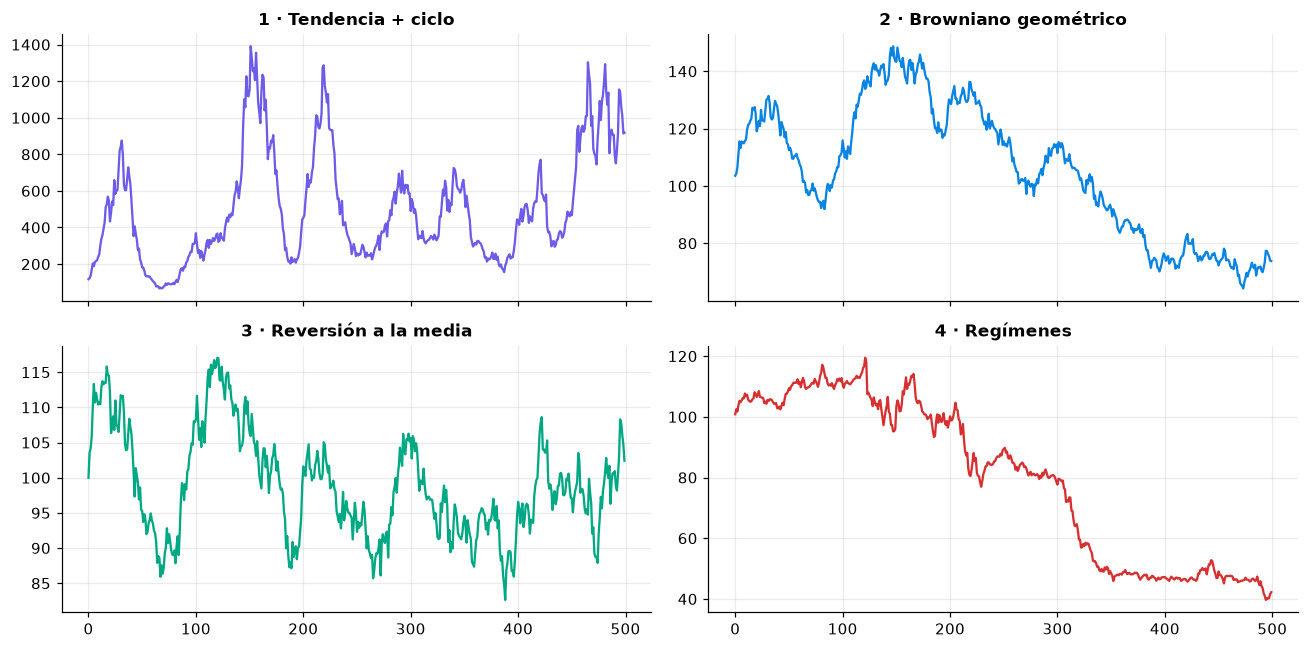

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for ax, m in zip(axes.flat, MARKETS):
    ax.plot(make_prices(m, N_STEPS, seed=0), color=MARKET_COLORS[m])
    ax.set_title(MARKET_LABELS[m])
fig.tight_layout()
savefig(fig, "00_mercados");

## 2. La observación que recibe la red

A diferencia del Taller 1 no hay que discretizar, pero la escala de la tendencia cambia mucho entre mercados (D-1.1).

In [3]:
def tendencias(mercado, n_series=20):
    salida = []
    for i in range(n_series):
        w = np.lib.stride_tricks.sliding_window_view(make_prices(mercado, N_STEPS, i), 6)
        salida.append((w[:, -1] - w.mean(axis=1)) / w.mean(axis=1))
    return np.concatenate(salida)

pd.DataFrame({MARKET_LABELS[m]: np.percentile(tendencias(m), [5, 50, 95]) for m in MARKETS},
             index=["p5", "p50", "p95"]).round(4)

,1 · Tendencia + ciclo,2 · Browniano geométrico,3 · Reversión a la media,4 · Regímenes
p5,-0.2231,-0.0398,-0.0382,-0.0450
p50,0.0153,-0.0008,-0.0002,0.0004
p95,0.2724,0.0393,0.0400,0.0360


## 3. Baselines en las 200 series de test

`aleatorio` y `buy_hold` reproducen los números del Taller 1 (lo comprueba `test_common.py`). Se añade `no_operar`.

In [4]:
filas = []
for mercado in MARKETS:
    for nombre, agente in baseline_agents().items():
        filas.append(summarize(nombre, mercado, evaluate(agente, mercado)))
baselines = save_results(filas, "00_baselines")
baselines.pivot(index="mercado", columns="agente", values="retorno_mediana").loc[list(MARKETS)].round(3)

agente,aleatorio,buy_hold,no_operar
mercado,,,
tendencia_ciclo,3.304,32.617,0.0
browniano,-0.194,-0.035,0.0
reversion_media,-0.172,-0.003,0.0
regimenes,-0.220,-0.125,0.0


## 4. Un episodio del agente aleatorio

La figura del enunciado, que se reutiliza para analizar cualquier agente.

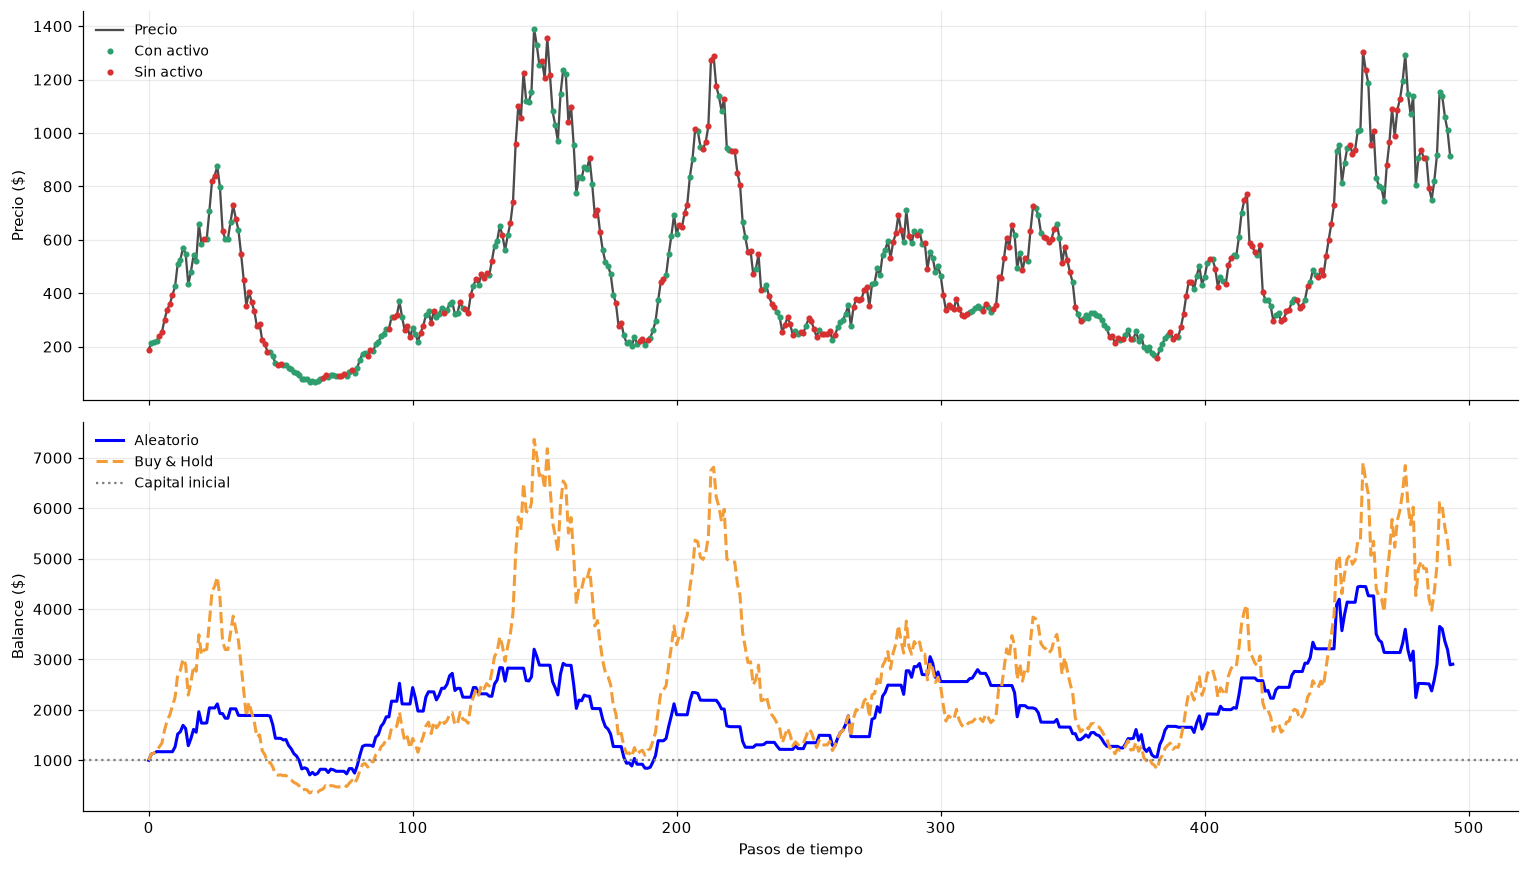

In [5]:
precios = make_prices("tendencia_ciclo", N_STEPS, seed=0)
_, balances, _, posiciones = run_episode(SimpleTradingEnv(precios), baseline_agents()["aleatorio"])
fig = plot_episode(precios, balances, posiciones, label="Aleatorio")
savefig(fig, "00_episodio_aleatorio");